**TIL4030-20 - Research Paper - Group 17**

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
services = pd.read_csv("data/services/services-2025-12.csv.gz")
disruptions = pd.read_csv("data/disruptions/disruptions-2025.csv")

print(services.shape, disruptions.shape)

(1839926, 20) (6676, 14)


In [21]:
# print(disruptions.head())
print(disruptions.columns)

Index(['rdt_id', 'ns_lines', 'rdt_lines', 'rdt_lines_id', 'rdt_station_names',
       'rdt_station_codes', 'cause_nl', 'cause_en', 'statistical_cause_nl',
       'statistical_cause_en', 'cause_group', 'start_time', 'end_time',
       'duration_minutes'],
      dtype='str')


In [31]:
# Station mapping
station_map = {}

for _, row in disruptions.dropna(
    subset=["rdt_station_codes", "rdt_station_names"]
).iterrows():
  codes = [c.strip() for c in str(row["rdt_station_codes"]).split(",")]
  names = [n.strip() for n in str(row["rdt_station_names"]).split(",")]
  if len(codes) == len(names):
    for code, name in zip(codes, names):
      if code and name and code not in station_map:
        station_map[code] = name

# Unnecessary columns
unwanted = ['rdt_id', 'ns_lines', 'rdt_lines', 'rdt_lines_id', 'rdt_station_names', 'cause_nl', 'cause_en', 'statistical_cause_nl']
disruptions = disruptions.drop(unwanted, axis=1)

# Initial test for December 2025
disruptions["start_dt"] = pd.to_datetime(disruptions["start_time"], errors="coerce")
disruptions = disruptions[(disruptions["start_dt"] >= "2025-12-01") & (disruptions["start_dt"] < "2026-01-01")].copy()

# Delete external disturbances and duration_minutes == 0
disruptions = disruptions[
    (disruptions["cause_group"].fillna("").str.strip().str.lower() != "external")
    & (disruptions["duration_minutes"].notna())
    & (disruptions["duration_minutes"] != 0)
].copy()
print(disruptions.head())

                           rdt_station_codes     statistical_cause_en  \
6157  GD, GDG, GVC, VB, YPB, ZTM, ZTMO, LLZM  defective railway track   
6158                                  HT, TB        broken down train   
6159                                AMF, APD           signal failure   
6160                            DN, HM, HMBH        broken down train   
6161                      BNC, BNN, HVL, BNZ           signal failure   

         cause_group           start_time             end_time  \
6157  infrastructure  2025-12-01 04:52:14  2025-12-01 19:17:37   
6158   rolling stock  2025-12-01 06:04:56  2025-12-01 06:37:58   
6159  infrastructure  2025-12-01 06:34:57  2025-12-01 11:58:37   
6160   rolling stock  2025-12-01 06:37:32  2025-12-01 06:48:00   
6161  infrastructure  2025-12-01 06:53:52  2025-12-01 11:58:33   

      duration_minutes            start_dt  
6157             865.0 2025-12-01 04:52:14  
6158              33.0 2025-12-01 06:04:56  
6159             324.0 2025-1

In [32]:
# 1. By disruption type
by_dis_type = disruptions.groupby("statistical_cause_en", dropna=False)["duration_minutes"].agg(
    count="count",
    total_min="sum",
    mean_min="mean",
    median_min="median",
    max_min="max",
).sort_values("count", ascending=False)

print(by_dis_type.round(1))



                                     count  total_min  mean_min  median_min  \
statistical_cause_en                                                          
broken down train                      195    10324.0      52.9        31.0   
stranded train                          69     3400.0      49.3        40.0   
collision                               32     4402.0     137.6       154.5   
signal failure                          24     3286.0     136.9        94.5   
technical investigation                 23     1887.0      82.0        65.0   
points failure                          21     2579.0     122.8       123.0   
defective railway track                 13     7016.0     539.7       254.0   
problems with the rolling stock         12     6052.0     504.3       429.0   
damaged overhead wires                   8     1725.0     215.6       184.5   
damaged railway bridge                   7      623.0      89.0        78.0   
railway problems abroad                  6     1989.

In [33]:
# 4. By railway station (explode rdt_station_codes)
by_station_df = disruptions.copy()
by_station_df["station_code"] = (
    by_station_df["rdt_station_codes"].fillna("").str.split(",")
)
by_station_df = by_station_df.explode("station_code")
by_station_df["station_code"] = by_station_df["station_code"].str.strip()
by_station_df = by_station_df[by_station_df["station_code"] != ""]
by_station_df["station_name"] = (
    by_station_df["station_code"].map(station_map).fillna(by_station_df["station_code"])
)

by_station = (
    by_station_df.groupby(["station_code", "station_name"], dropna=False)[
        "duration_minutes"
    ]
    .agg(
        count="count",
        total_min="sum",
        mean_min="mean",
        median_min="median",
    )
    .sort_values("count", ascending=False)
    .reset_index()
)

by_station_cause = (
    by_station_df.groupby(
        ["station_code", "station_name", "statistical_cause_en"], dropna=False
    )["duration_minutes"]
    .agg(
        count="count",
        total_min="sum",
        mean_min="mean",
        median_min="median",
    )
    .sort_values("total_min", ascending=False)
    .reset_index()
)

print("\n--- Top 10 stations by frequency ---")
print(by_station.head(10).round(1))

print("\n--- Top 10 (station, statistical_cause_en) by total duration ---")
print(by_station_cause.head(10).round(1))


--- Top 10 stations by frequency ---
  station_code         station_name  count  total_min  mean_min  median_min
0          RTD   Rotterdam Centraal     77     5783.0      75.1        47.0
1          SHL     Schiphol Airport     50     4110.0      82.2        59.5
2           BD                Breda     42     2457.0      58.5        37.0
3          AMF  Amersfoort Centraal     31     3631.0     117.1        62.0
4           WP                Weesp     30     2420.0      80.7        53.5
5         ASDZ       Amsterdam Zuid     30     2419.0      80.6        42.5
6           UT     Utrecht Centraal     25     3409.0     136.4        81.0
7          DVD         Duivendrecht     25     3039.0     121.6        74.0
8          DDR            Dordrecht     22     2245.0     102.0        63.0
9          GVC    Den Haag Centraal     21     2756.0     131.2        70.0

--- Top 10 (station, statistical_cause_en) by total duration ---
  station_code           station_name             statistica

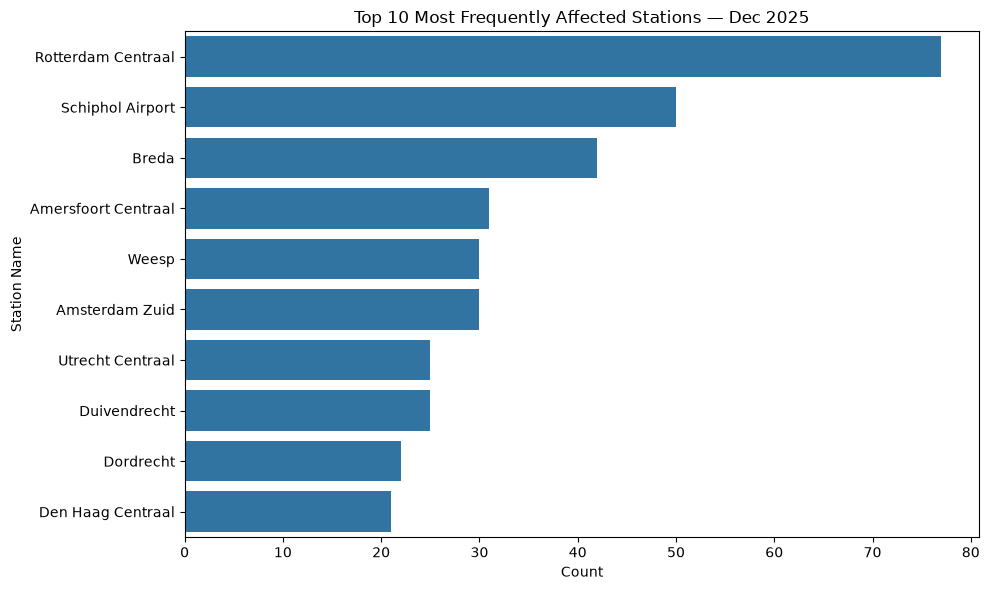

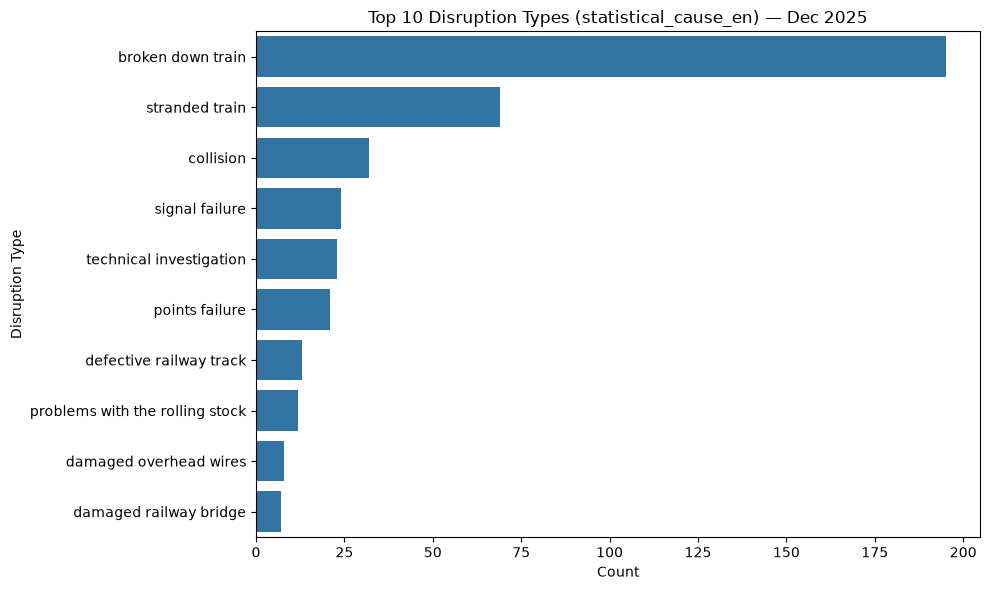

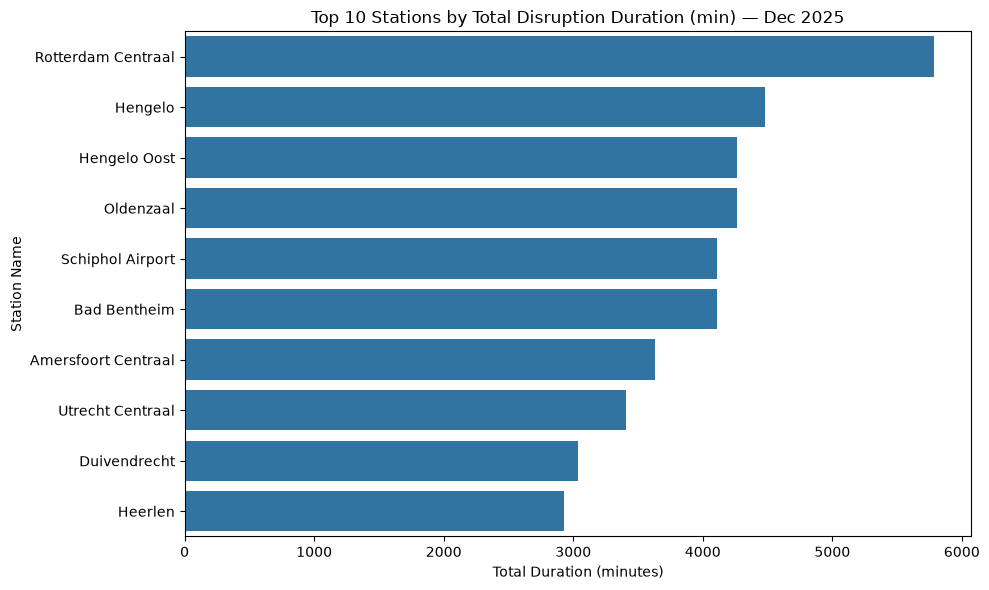

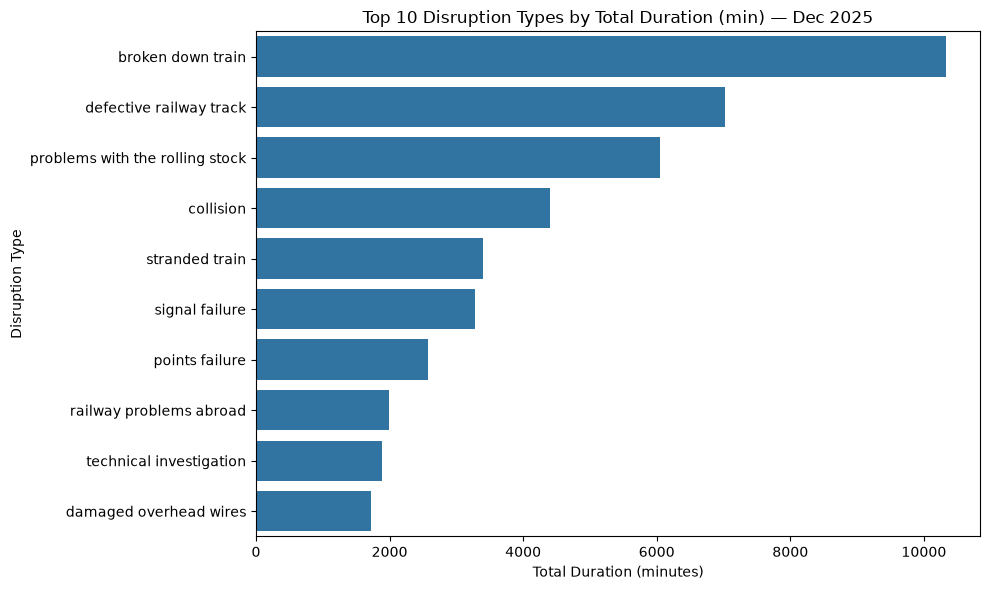

In [36]:
# --- Bar chart 1: Top 10 Stations with the most disruptions - Dec 2025 ---
top10_stations = by_station.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(data=top10_stations, x="count", y="station_name")
plt.title("Top 10 Most Frequently Affected Stations — Dec 2025")
plt.xlabel("Count")
plt.ylabel("Station Name")
plt.tight_layout()
plt.show()

# --- Bar chart 2: Top 10 most frequent disruption types - Dec 2025 ---
top10_dis_type = by_dis_type.head(10).reset_index()
plt.figure(figsize=(10, 6))
sns.barplot(data=top10_dis_type, x="count", y="statistical_cause_en")
plt.title("Top 10 Disruption Types (statistical_cause_en) — Dec 2025")
plt.xlabel("Count")
plt.ylabel("Disruption Type")
plt.tight_layout()
plt.show()

# --- Bar chart 3: Top 10 stations by total duration of disruptions (total_min) ---
top10_dur_stations = by_station.sort_values("total_min", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top10_dur_stations, x="total_min", y="station_name")
plt.title("Top 10 Stations by Total Disruption Duration (min) — Dec 2025")
plt.xlabel("Total Duration (minutes)")
plt.ylabel("Station Name")
plt.tight_layout()
plt.show()

# --- Bar chart 4: Top 10 disruption types by total duration ---
top10_dur_types = (
    by_dis_type.sort_values("total_min", ascending=False).head(10).reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(data=top10_dur_types, x="total_min", y="statistical_cause_en")
plt.title("Top 10 Disruption Types by Total Duration (min) — Dec 2025")
plt.xlabel("Total Duration (minutes)")
plt.ylabel("Disruption Type")
plt.tight_layout()
plt.show()

Q1: 24.0, Q3: 123.0, IQR: 99.0, Upper fence (Q3 + 1.5*IQR): 271.5
High outliers count: 42 out of 437
               start_time  duration_minutes     cause_group  \
6401  2025-12-13 17:40:13            2105.0  infrastructure   
6325  2025-12-09 14:47:47            1424.0  infrastructure   
6636  2025-12-30 04:25:09             981.0   rolling stock   
6232  2025-12-04 06:57:06             948.0   rolling stock   
6614  2025-12-28 07:28:25             932.0   rolling stock   
6157  2025-12-01 04:52:14             865.0  infrastructure   
6235  2025-12-04 10:25:37             861.0      logistical   
6629  2025-12-29 14:08:11             626.0  infrastructure   
6586  2025-12-26 14:14:31             619.0  infrastructure   
6399  2025-12-13 12:45:31             581.0      logistical   

                 statistical_cause_en                       rdt_station_codes  
6401          defective railway track                      HT, HTO, O, OW, RS  
6325          defective railway track        

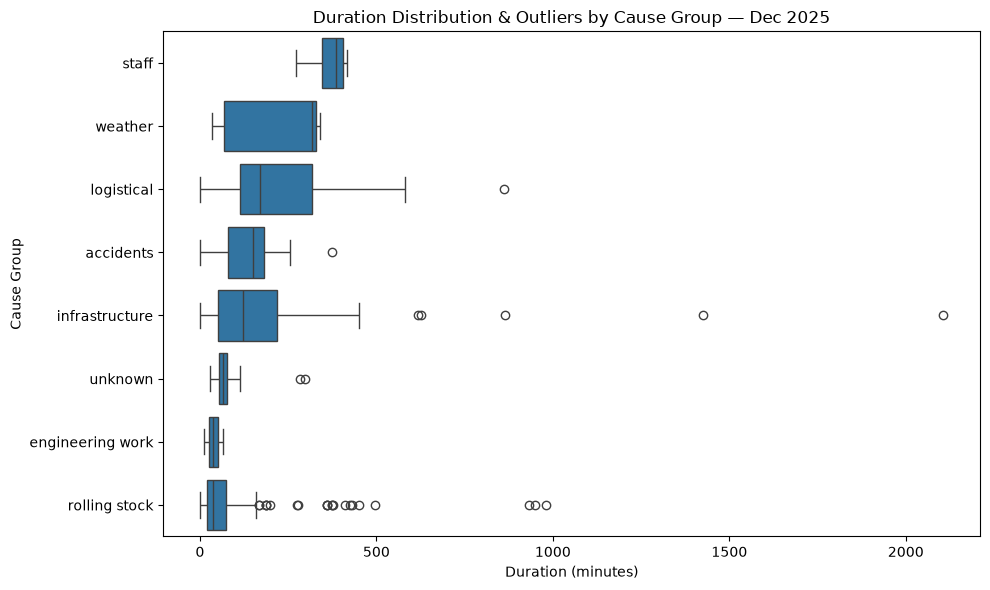

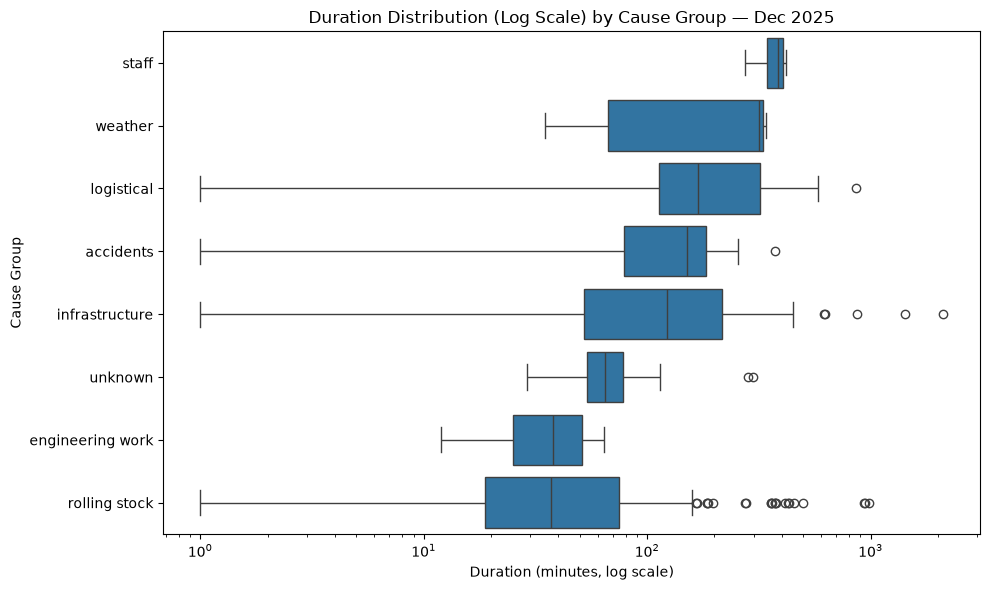

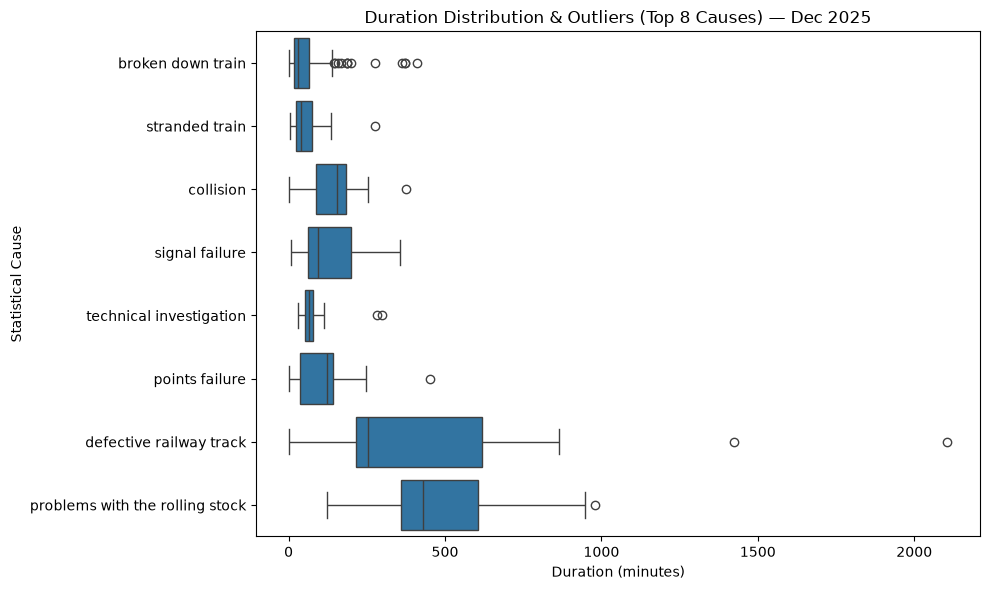

In [37]:
# --- 1. Οutlier check (IQR method) for duration ---
q1 = disruptions["duration_minutes"].quantile(0.25)
q3 = disruptions["duration_minutes"].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

outliers_high = disruptions[disruptions["duration_minutes"] > upper_fence].sort_values(
    "duration_minutes", ascending=False
)

print(f"Q1: {q1:.1f}, Q3: {q3:.1f}, IQR: {iqr:.1f}, Upper fence (Q3 + 1.5*IQR): {upper_fence:.1f}")
print(f"High outliers count: {len(outliers_high)} out of {len(disruptions)}")
print(
    outliers_high[
        ["start_time", "duration_minutes", "cause_group", "statistical_cause_en", "rdt_station_codes"]
    ].head(10)
)

# --- 2. Boxplot: Duration distribution and outliers by cause_group
group_order = (
    disruptions.groupby("cause_group")["duration_minutes"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(10, 6))
sns.boxplot(data=disruptions, x="duration_minutes", y="cause_group", order=group_order)
plt.title("Duration Distribution & Outliers by Cause Group — Dec 2025")
plt.xlabel("Duration (minutes)")
plt.ylabel("Cause Group")
plt.tight_layout()
plt.show()

# --- 3. Boxplot (log scale): Duration distribution and outliers by cause_group
plt.figure(figsize=(10, 6))
sns.boxplot(data=disruptions, x="duration_minutes", y="cause_group", order=group_order)
plt.xscale("log")
plt.title("Duration Distribution (Log Scale) by Cause Group — Dec 2025")
plt.xlabel("Duration (minutes, log scale)")
plt.ylabel("Cause Group")
plt.tight_layout()
plt.show()

# --- 4. Boxplot for the Top 8 most frequent statistical_cause_en ---
top8_causes = (
    disruptions["statistical_cause_en"].value_counts().head(8).index
)
sub_causes = disruptions[disruptions["statistical_cause_en"].isin(top8_causes)]

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=sub_causes,
    x="duration_minutes",
    y="statistical_cause_en",
    order=top8_causes,
)
plt.title("Duration Distribution & Outliers (Top 8 Causes) — Dec 2025")
plt.xlabel("Duration (minutes)")
plt.ylabel("Statistical Cause")
plt.tight_layout()
plt.show()